# 7.6 · 部署与运维

> 策略要长期稳定运行，靠的是部署与运维（DevOps）：进程管理、定时调度、数据库、版本管理、容器化、监控、灰度上线。
> 本节建立完整的工程化上线认知，理解一套量化系统如何从开发环境安全地跑到生产环境并持续维护。

## 一、进程管理

实盘程序需要长期驻留、崩溃后自动重启：
- Linux：systemd、supervisor；Windows：服务/计划任务 + 守护脚本；
- 容器编排：Docker Compose、Kubernetes；
- 要求：开机自启、异常自动重启、进程状态可监控、日志可收集。

## 二、定时任务与调度

| 任务 | 触发时机 |
|---|---|
| 数据更新 | 收盘后 |
| 盘前准备 | 开盘前 |
| 实时交易 | 交易时段 |
| 对账/报告 | 收盘后 |
- Linux 用 cron、Windows 用任务计划程序，复杂调度用 Airflow/自研调度器；
- 任务要可重试、失败会报警、有依赖顺序。

## 三、数据库与存储

| 数据类型 | 选型 |
|---|---|
| 行情/tick（时序） | ClickHouse、InfluxDB、DolphinDB、kdb+ |
| 订单/持仓/账户（事务） | PostgreSQL、MySQL |
| 缓存/消息 | Redis、Kafka |
| 文件/特征 | Parquet、对象存储、Qlib bin |

- 数据模型要保证 PIT 和一致性；关键数据定期备份；
- 时序库擅长高写入和按时间查询，关系库保证事务和对账。

## 四、版本、配置与环境管理

In [1]:
# 健康检查：上线前确认各组件就绪（可纳入部署脚本）
def health_check(checks):
    result = {}
    for name, ok in checks.items():
        result[name] = 'OK' if ok else 'FAIL'
    return result
hc = health_check({'config_loaded': True, 'data_ready': True,
                   'broker_connected': True, 'risk_loaded': True,
                   'logs_writable': True})
for k, v in hc.items():
    print('%-16s %s' % (k, v))
print('全部就绪:', all(x == 'OK' for x in hc.values()))

config_loaded    OK
data_ready       OK
broker_connected OK
risk_loaded      OK
logs_writable    OK
全部就绪: True


- **版本管理（Git）**：代码、策略、配置全部纳入版本控制，记录每次变更，可回滚；
- **配置管理**：环境差异（开发/模拟/生产）用配置文件或环境变量，敏感信息不入库；
- **环境管理**：conda/容器固定依赖版本，保证可复现；
- **分支策略**：主干稳定，新策略在分支开发、测试通过再合并。

## 五、容器化与 CI/CD

- **Docker 容器**：把代码、依赖、环境打包，开发/测试/生产环境一致，便于部署和扩容；
- **CI（持续集成）**：提交后自动跑测试、代码检查；
- **CD（持续交付）**：自动构建镜像、按流程发布，支持灰度和回滚；
- 好处：减少"我机器上能跑"的问题，发布可追溯、可回退。

## 六、上线流程（灰度发布）

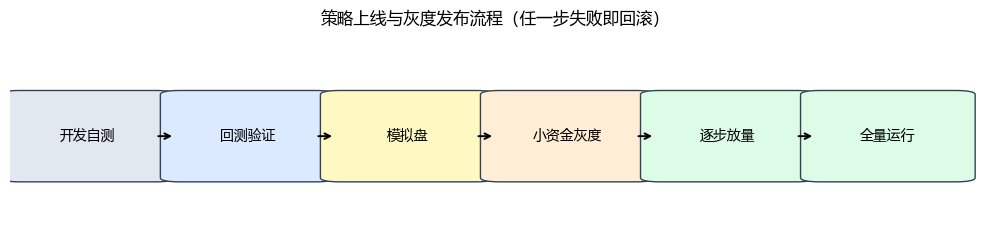

In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as mp
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(10, 2.6)); ax.axis('off')
stages = ['开发自测', '回测验证', '模拟盘', '小资金灰度', '逐步放量', '全量运行']
colors = ['#e2e8f0', '#dbeafe', '#fef9c3', '#ffedd5', '#dcfce7', '#dcfce7']
for i, (s, c) in enumerate(zip(stages, colors)):
    x = 0.01 + i * 0.165
    ax.add_patch(mp.FancyBboxPatch((x, 0.3), 0.14, 0.4,
                 boxstyle='round,pad=0.02', fc=c, ec='#334155'))
    ax.text(x+0.07, 0.5, s, ha='center', va='center', fontsize=10)
    if i < len(stages)-1:
        ax.annotate('', xy=(x+0.16, 0.5), xytext=(x+0.14, 0.5),
                    arrowprops=dict(arrowstyle='->', lw=1.4))
ax.set_title('策略上线与灰度发布流程（任一步失败即回滚）', fontsize=12)
plt.tight_layout(); plt.show()

## 七、监控、告警与回滚

- 生产环境持续监控（系统/交易/盈亏/数据），异常分级告警；
- 日志集中收集，便于排查和审计；
- 灰度期间发现问题立即停止放量、回滚到上一稳定版本；
- 定期容灾演练，确认备份可恢复、故障可切换。

## 八、小结与面试要点

- 部署运维：进程守护、定时调度、时序+关系数据库、Git/配置/环境管理、Docker 与 CI/CD、灰度上线与回滚。
- 上线遵循"回测→模拟→小资金→放量"，每步可回滚；健康检查与监控贯穿始终。

**面试高频：**
- 怎么保证实盘程序长期稳定运行？（答：进程守护自动重启、监控告警、日志、容灾备份）
- 为什么用容器/CI-CD？（答：环境一致、自动测试发布、可回滚、可追溯）
- 策略怎么安全上线？（答：灰度发布、小资金验证、异常即回滚）
- 行情和交易数据分别用什么存储？（答：时序库存行情，关系库存订单账户）

## 动手练习
1. 写出你策略的部署清单和健康检查项；
2. 设计一个收盘后自动跑的任务序列（数据更新→对账→报告）；
3. 列出从开发到生产的完整发布与回滚步骤。

---
**L1 实盘工程（7.1–7.6）到此全部完成。** 下一阶段进入 L2 模块纵深，从 B1 数据与微观结构开始。